Import dataset for student performance prediction system from **ucimlrepo**

In [23]:
!pip install ucimlrepo

In [24]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42


Load Student Performance Dataset

In [25]:
# fetch dataset
student_performance = fetch_ucirepo(id=320)

# data (as pandas dataframes)
X = student_performance.data.features.copy()
y = student_performance.data.targets.copy()

# Dataset
print("Dataset: ",student_performance.metadata.get("name", "Student Performance"))

# Feature & Target
print("Feature shape: ", X.shape)
print("\nTarget columns: ", list(y.columns))

# header of X & y
display(X.head())
display(y.head())

Dataset:  Student Performance
Feature shape:  (649, 30)

Target columns:  ['G1', 'G2', 'G3']


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,yes,no,no,4,3,4,1,1,3,4
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,yes,no,5,3,3,1,1,3,2
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,yes,no,4,3,2,2,3,3,6
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,yes,3,2,2,1,1,5,0
4,GP,F,16,U,GT3,T,3,3,other,other,...,yes,no,no,4,3,2,1,2,5,0


,G1,G2,G3
0,0,11,11
1,9,11,11
2,12,13,12
3,14,14,14
4,11,13,13


Data preparation

In [26]:
# 4. Prepare the data
# Use G3 from the targets table when available; otherwise use G3 from the
# combined table. This avoids accidentally using the target as an input.
data = X.copy()
for column in y.columns:
    if column not in data.columns:
        data[column] = y[column]

if "G3" in y.columns:
    target = pd.to_numeric(y["G3"], errors="coerce").rename("G3")
elif "G3" in data.columns:
    target = pd.to_numeric(data["G3"], errors="coerce").rename("G3")
else:
    raise ValueError("The final-grade column 'G3' was not found in this dataset.")

# Predict final grade G3. Exclude G1 and G2 to make this an early prediction.
X = data.drop(columns=["G3", "G1", "G2"], errors="ignore").copy()
valid_rows = target.notna()
X = X.loc[valid_rows].copy()
y = target.loc[valid_rows].copy()

# Remove columns that contain no values.
X = X.dropna(axis=1, how="all")

print("Number of students:", len(X))
print("Number of input features:", X.shape[1])
print("Target: final grade (G3)")
display(pd.DataFrame({"Final grade (G3)": y}).head())

Number of students: 649
Number of input features: 30
Target: final grade (G3)


,Final grade (G3)
0,11
1,11
2,12
3,14
4,13


Split **data** and train the **model**

In [33]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

#Identify numeric and categorical columns
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()
categorical_columns = X_train.select_dtypes(exclude="number").columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("encore", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# Create and train the model
model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)
print("Model Tarining Completed.")
print("Training records:", len(X_train))
print("Training records:", len(X_test))

Model Tarining Completed.
Training records: 519
Training records: 130


Evaluation of model

Mean Absolute Error (MAE): 2.16
Root Mean Square Error (RMSE): 2.86
R^2 Score: 0.160


,Actual grade,Predicted grade
636,19,13.07
220,12,12.97
594,18,14.02
429,11,12.00
72,11,10.36
448,17,12.69
181,18,13.83
131,8,6.67
231,10,12.56
277,11,12.16


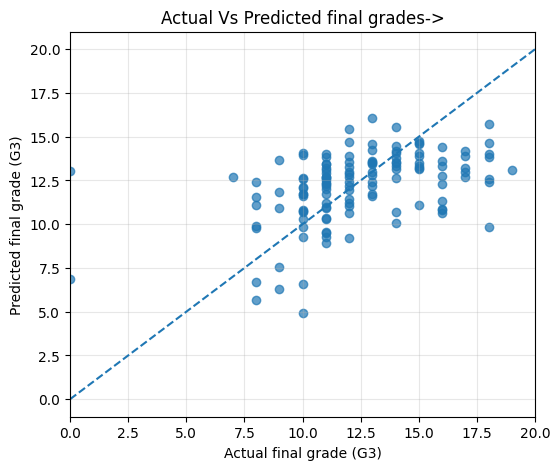

In [35]:
# Evalute the model
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = mean_squared_error(y_test, predictions)** 0.5
r2 = r2_score(y_test, predictions)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Square Error (RMSE): {rmse:.2f}")
print(f"R^2 Score: {r2:.3f}")

# Compare a few actual grades with predicted grades
comparison = pd.DataFrame({
    "Actual grade": y_test,
    "Predicted grade": predictions
})
display(comparison.head(10).round(2))

plt.figure(figsize=(6, 5))
plt.scatter(y_test, predictions, alpha=0.7)
plt.xlabel("Actual final grade (G3)")
plt.ylabel("Predicted final grade (G3)")
plt.title("Actual Vs Predicted final grades->")
plt.plot([0,20], [0,20], linestyle="--")
plt.xlim(0,20)
plt.grid(True, alpha=0.3)
plt.show()

Make a Prediction

In [36]:
# 7. Predict the final grade for one student
sample_student = X_test.iloc[[0]]
predicted_grade = float(model.predict(sample_student)[0])
predicted_grade = max(0.0, min(20.0, predicted_grade))

print(f"Predicted final grade: {predicted_grade:.2f} / 20")
print("\nStudent input details:")
display(sample_student.T.rename(columns={sample_student.index[0]: "Value"}))

Predicted final grade: 13.07 / 20

Student input details:


,Value
school,MS
sex,M
age,18
address,U
famsize,GT3
Pstatus,T
Medu,4
Fedu,4
Mjob,teacher
Fjob,teacher


In [37]:
# 8. Reusable function for another student record
def predict_student_performance(student_features):
    """Predict final grade G3 from a dictionary of feature values.

    Use the same feature names as X.columns. Missing input fields are
    handled by the preprocessing pipeline.
    """
    student_row = pd.DataFrame([student_features]).reindex(columns=X.columns)
    grade = float(model.predict(student_row)[0])
    return max(0.0, min(20.0, grade))

# Example: reuse the first test student's details
example_student = X_test.iloc[0].to_dict()
print(f"Example prediction: {predict_student_performance(example_student):.2f} / 20")

Example prediction: 13.07 / 20
